<a href="https://colab.research.google.com/github/anupbagale/segmentation-volumes/blob/main/notebooks/01_label_volumes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Volume of each label in a segmentation

A segmentation stores one integer label per voxel. Every voxel is a small box of known size, so
the volume of a structure is simply

$$\text{volume} = \text{number of voxels with that label} \times \text{volume of one voxel}$$

This notebook measures the volume of all 45 structures in a FreeSurfer brain segmentation, adds
their names, compares the left and right hemispheres, and shows how much the result depends on the
voxel size.

The data is the "sample" subject from the MNE-Python project (CC0), a FreeSurfer `aseg`
segmentation downsampled to 3 mm voxels. The first version of this notebook used a scan from the
OASIS-3 dataset, which cannot be shared publicly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path
import urllib.request

try:
    import nibabel as nib
except ImportError:                               # not installed yet, e.g. on Colab
    %pip install -q nibabel
    import nibabel as nib

DATA_URL = "https://raw.githubusercontent.com/anupbagale/segmentation-volumes/main/data/"


def data_file(name):
    """Use the file from the repository's data folder, or download it (e.g. on Colab)."""
    for folder in (Path("../data"), Path("data")):
        if (folder / name).exists():
            return folder / name
    Path("data").mkdir(exist_ok=True)
    urllib.request.urlretrieve(DATA_URL + name, Path("data") / name)
    return Path("data") / name

## Voxel size

The image header stores the size of a voxel in millimetres along each axis. Their product is the
volume of one voxel. Only the first three values are used: a 4D image (for example a time series)
has a fourth value for the time step, which is not a length.

In [3]:
img = nib.load(data_file("aseg.mgz"))
seg = np.asarray(img.dataobj).astype(int)

zooms = img.header.get_zooms()[:3]
voxel_mm3 = float(np.prod(zooms))
print("image shape:", seg.shape)
print("voxel size (mm):", [float(z) for z in zooms])
print("one voxel:", voxel_mm3, "mm³")

image shape: (86, 86, 86)
voxel size (mm): [3.0, 3.0, 3.0]
one voxel: 27.0 mm³


The first version of this notebook printed volumes like `179362.04276323318`. The voxel size in
that file was stored as a 32-bit float slightly above 1.0 (for example 1.0000002), and every
volume inherited the tiny error. Rounding to a sensible number of digits hides that noise.

## Volume of the whole image

The total number of voxels times the voxel volume is the size of the box the image covers, not
the size of the brain. Most of that box is air around the head.

In [4]:
fov_mm3 = seg.size * voxel_mm3
print(f"field of view: {seg.shape[0] * zooms[0]:.0f} x {seg.shape[1] * zooms[1]:.0f} x "
      f"{seg.shape[2] * zooms[2]:.0f} mm = {fov_mm3 / 1e6:.1f} litres")

field of view: 258 x 258 x 258 mm = 17.2 litres


## Counting voxels per label

`np.bincount` counts how often every integer appears, in one pass over the image. The first
version compared the whole image with each label in turn (`np.sum(image_data == label)`), which
gives the same numbers but goes over the data 45 times.

In [5]:
counts = np.bincount(seg.ravel())
labels = np.flatnonzero(counts)
print(len(labels), "labels including background:", labels)

# same result as the per-label loop
assert all(counts[label] == np.sum(seg == label) for label in labels)

46 labels including background: [  0   2   3   4   5   7   8  10  11  12  13  14  15  16  17  18  24  26
  28  30  31  41  42  43  44  46  47  49  50  51  52  53  54  58  60  62
  63  72  77  80  85 251 252 253 254 255]


## Adding names

The label numbers only mean something together with FreeSurfer's lookup table, which gives a
name for each one.

In [6]:
names = {}
with open(data_file("aseg_lut.txt")) as f:
    for line in f:
        parts = line.split()
        if parts and not parts[0].startswith("#"):
            names[int(parts[0])] = parts[1]

table = pd.DataFrame({
    "label": labels,
    "name": [names.get(int(l), "") for l in labels],
    "voxels": counts[labels],
})
table["volume_cm3"] = (table["voxels"] * voxel_mm3 / 1000).round(2)
table = table[table["label"] != 0]                # drop the background

table.sort_values("volume_cm3", ascending=False).head(12)

,label,name,voxels,volume_cm3
1,2,Left-Cerebral-White-Matter,10477,282.88
21,41,Right-Cerebral-White-Matter,10151,274.08
22,42,Right-Cerebral-Cortex,9428,254.56
2,3,Left-Cerebral-Cortex,9130,246.51
26,47,Right-Cerebellum-Cortex,1943,52.46
6,8,Left-Cerebellum-Cortex,1885,50.90
13,16,Brain-Stem,902,24.35
5,7,Left-Cerebellum-White-Matter,630,17.01
25,46,Right-Cerebellum-White-Matter,510,13.77
3,4,Left-Lateral-Ventricle,414,11.18


## Checking the numbers

Every voxel has exactly one label, so the volumes of all labels including the background must add
up to the field of view. The total of the non-zero labels is the segmented brain volume.

In [7]:
background_cm3 = counts[0] * voxel_mm3 / 1000
brain_cm3 = table["volume_cm3"].sum()
print(f"background + all structures = {background_cm3 + brain_cm3:,.0f} cm³")
print(f"field of view               = {fov_mm3 / 1000:,.0f} cm³")
print()
print(f"segmented brain volume: {brain_cm3:,.0f} cm³")
for side in ["Left", "Right"]:
    print(f"  {side.lower()} structures: {table[table['name'].str.startswith(side)]['volume_cm3'].sum():,.0f} cm³")
ventricles = table[table["name"].str.contains("Ventricle|Inf-Lat-Vent")]
print(f"  all ventricles:   {ventricles['volume_cm3'].sum():,.1f} cm³  ({', '.join(ventricles['name'])})")

background + all structures = 17,174 cm³
field of view               = 17,174 cm³

segmented brain volume: 1,309 cm³
  left structures: 641 cm³
  right structures: 635 cm³
  all ventricles:   22.8 cm³  (Left-Lateral-Ventricle, Left-Inf-Lat-Vent, 3rd-Ventricle, 4th-Ventricle, Right-Lateral-Ventricle, Right-Inf-Lat-Vent, 5th-Ventricle)


## Left and right

Most structures exist once in each hemisphere. Putting the pairs next to each other shows how
symmetric the brain is. The asymmetry index is the difference divided by the mean,
$(L - R) / \tfrac{1}{2}(L + R)$, so 0.1 means the left side is about 10% larger.

In [8]:
left = table[table["name"].str.startswith("Left-")].copy()
left["structure"] = left["name"].str.replace("Left-", "", regex=False)
right = table[table["name"].str.startswith("Right-")].copy()
right["structure"] = right["name"].str.replace("Right-", "", regex=False)

pairs = left.merge(right, on="structure", suffixes=("_left", "_right"))
pairs = pairs[["structure", "volume_cm3_left", "volume_cm3_right"]]
pairs["asymmetry"] = ((pairs["volume_cm3_left"] - pairs["volume_cm3_right"])
                      / ((pairs["volume_cm3_left"] + pairs["volume_cm3_right"]) / 2)).round(2)
pairs = pairs.sort_values("volume_cm3_left", ascending=False).reset_index(drop=True)
pairs

,structure,volume_cm3_left,volume_cm3_right,asymmetry
0,Cerebral-White-Matter,282.88,274.08,0.03
1,Cerebral-Cortex,246.51,254.56,-0.03
2,Cerebellum-Cortex,50.90,52.46,-0.03
3,Cerebellum-White-Matter,17.01,13.77,0.21
4,Lateral-Ventricle,11.18,8.61,0.26
5,Thalamus,7.91,8.72,-0.10
6,Putamen,5.75,5.48,0.05
7,VentralDC,4.35,3.92,0.10
8,Caudate,4.02,3.81,0.05
9,Hippocampus,3.94,4.08,-0.03


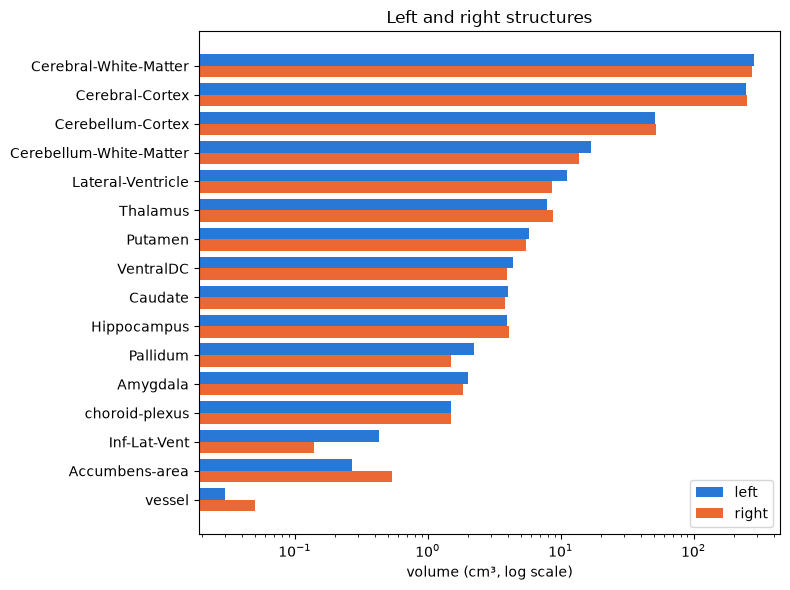

In [9]:
y = np.arange(len(pairs))
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(y - 0.2, pairs["volume_cm3_left"], height=0.4, label="left", color="#2a78d6")
ax.barh(y + 0.2, pairs["volume_cm3_right"], height=0.4, label="right", color="#eb6834")
ax.set_yticks(y, pairs["structure"])
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("volume (cm³, log scale)")
ax.set_title("Left and right structures")
ax.legend()
plt.tight_layout()
plt.show()

The cerebral white matter, the cortex and the cerebellar cortex are within 3% between the two
sides. The small structures differ much more, partly because at 3 mm a structure like the accumbens is only
about ten voxels, so one voxel more or less changes its volume by about 10%.

## How much does the voxel size matter?

To see this directly, keep every second voxel in each direction. That gives the same brain at 6 mm,
where each voxel is 8 times larger, and the volumes can be measured again.

In [10]:
coarse = seg[::2, ::2, ::2]
coarse_counts = np.bincount(coarse.ravel(), minlength=counts.size)
coarse_mm3 = voxel_mm3 * 8

compare = table[["label", "name", "volume_cm3"]].rename(columns={"volume_cm3": "3 mm"}).copy()
compare["6 mm"] = (coarse_counts[compare["label"]] * coarse_mm3 / 1000).round(2)
compare["change %"] = ((compare["6 mm"] - compare["3 mm"]) / compare["3 mm"] * 100).round(0) + 0.0

names_to_show = ["Left-Cerebral-White-Matter", "Left-Cerebral-Cortex", "Brain-Stem",
                 "Left-Hippocampus", "Left-Amygdala", "Left-Accumbens-area",
                 "3rd-Ventricle", "Left-vessel", "CC_Posterior"]
compare.set_index("name").loc[names_to_show]

,label,3 mm,6 mm,change %
name,,,,
Left-Cerebral-White-Matter,2,282.88,289.01,2.0
Left-Cerebral-Cortex,3,246.51,246.02,0.0
Brain-Stem,16,24.35,25.92,6.0
Left-Hippocampus,17,3.94,3.46,-12.0
Left-Amygdala,18,2.00,1.73,-14.0
Left-Accumbens-area,26,0.27,0.22,-19.0
3rd-Ventricle,14,1.00,0.00,-100.0
Left-vessel,30,0.03,0.00,-100.0
CC_Posterior,251,0.65,0.00,-100.0


Large structures barely change. Small and thin ones can grow, shrink or disappear completely,
because whether they are hit by the remaining voxels is largely luck. The same effect applies,
less strongly, to the 3 mm data used here: published FreeSurfer volumes come from 1 mm scans and
also correct for voxels that are only partly inside a structure, so the numbers in this notebook
are approximate.

## Saving the table

In [11]:
table.to_csv("volumes.csv", index=False)
print(open("volumes.csv").read()[:300], "...")

label,name,voxels,volume_cm3
2,Left-Cerebral-White-Matter,10477,282.88
3,Left-Cerebral-Cortex,9130,246.51
4,Left-Lateral-Ventricle,414,11.18
5,Left-Inf-Lat-Vent,16,0.43
7,Left-Cerebellum-White-Matter,630,17.01
8,Left-Cerebellum-Cortex,1885,50.9
10,Left-Thalamus,293,7.91
11,Left-Caudate,149,4.02
12,L ...


`label_volumes.py` in this repository does the same for any `.nii`, `.nii.gz` or `.mgz` label
image from the command line:

```bash
python label_volumes.py aseg.mgz --lut aseg_lut.txt --output volumes.csv
```